# 08 · Contours and shape analysis

**Level:** Intermediate  
**Prerequisites:** Notebooks 01–07; masks, morphology, and edges.

## What you will build and learn

- Extract and visualize contour hierarchy.
- Measure area, perimeter, centroid, and circularity.
- Compare contour geometry with pixel counts.
- Create an explainable synthetic part inspector.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Generate an inspectable binary scene
Contours describe boundaries of nonzero regions. Start from a clean binary mask so you can separate geometry mistakes from thresholding mistakes. Coordinates use `(x, y)`; NumPy indexing uses `[y, x]`.


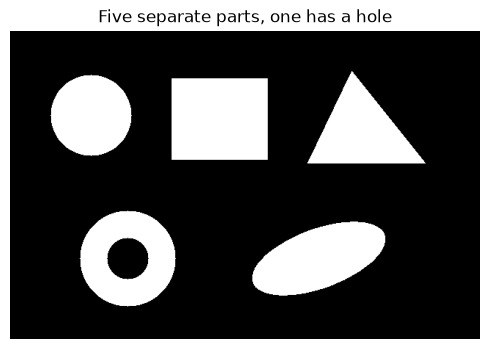

In [2]:
mask = np.zeros((420, 640), np.uint8)
cv2.circle(mask, (110, 115), 55, 255, -1)
cv2.rectangle(mask, (220, 65), (350, 175), 255, -1)
triangle = np.array([[465, 55], [405, 180], [565, 180]], np.int32)
cv2.fillPoly(mask, [triangle], 255)
cv2.circle(mask, (160, 310), 65, 255, -1)
cv2.circle(mask, (160, 310), 28, 0, -1)
cv2.ellipse(mask, (420, 310), (95, 40), -20, 0, 360, 255, -1)
show_images([mask], ['Five separate parts, one has a hole'])


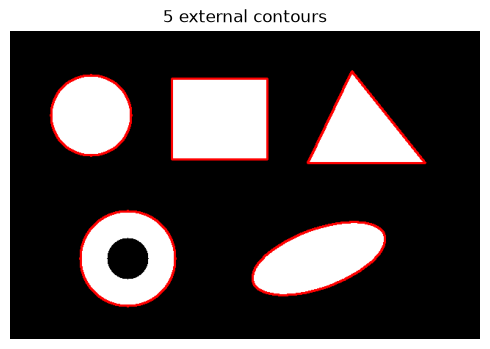

In [3]:
contours, hierarchy = cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)
canvas = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
cv2.drawContours(canvas, contours, -1, (0, 0, 255), 2)
show_images([canvas], [f'{len(contours)} external contours'])
assert len(contours) == 5, 'The generated parts should be disconnected.'


## Step 2 — Measure shapes and guard degenerate cases
`contourArea` integrates the polygon boundary; `arcLength(..., True)` measures a closed perimeter. Moments give centroid `(m10/m00, m01/m00)` when `m00 != 0`. A line or point can have zero area, so guard division. Pixel area and polygon area are related but not identical.


In [4]:
def shape_record(contour):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    moments = cv2.moments(contour)
    center = None if moments['m00'] == 0 else (moments['m10'] / moments['m00'],
                                               moments['m01'] / moments['m00'])
    x, y, w, h = cv2.boundingRect(contour)
    circularity = 4 * np.pi * area / perimeter**2 if perimeter > 0 else 0.0
    hull_area = cv2.contourArea(cv2.convexHull(contour))
    solidity = area / hull_area if hull_area > 0 else 0.0
    return dict(area=area, perimeter=perimeter, center=center, box=(x, y, w, h),
                circularity=circularity, solidity=solidity, aspect=w / h)

records = [shape_record(c) for c in contours]
for i, record in enumerate(records):
    print(i, {k: round(v, 3) if isinstance(v, float) else v for k, v in record.items()})


0 {'area': 14300.0, 'perimeter': 480.0, 'center': (285.0, 120.0), 'box': (220, 65, 131, 111), 'circularity': 0.78, 'solidity': 1.0, 'aspect': 1.18}
1 {'area': 13090.0, 'perimeter': 428.617, 'center': (160.0, 310.0), 'box': (95, 245, 131, 131), 'circularity': 0.895, 'solidity': 0.992, 'aspect': 1.0}
2 {'area': 11915.0, 'perimeter': 468.617, 'center': (419.990809903483, 310.0049517415023), 'box': (330, 260, 181, 101), 'circularity': 0.682, 'solidity': 0.989, 'aspect': 1.792}
3 {'area': 10000.0, 'perimeter': 476.274, 'center': (478.32516666666663, 138.34383333333332), 'box': (405, 55, 161, 126), 'circularity': 0.554, 'solidity': 0.99, 'aspect': 1.278}
4 {'area': 9322.0, 'perimeter': 362.676, 'center': (110.0, 115.0), 'box': (55, 60, 111, 111), 'circularity': 0.891, 'solidity': 0.99, 'aspect': 1.0}


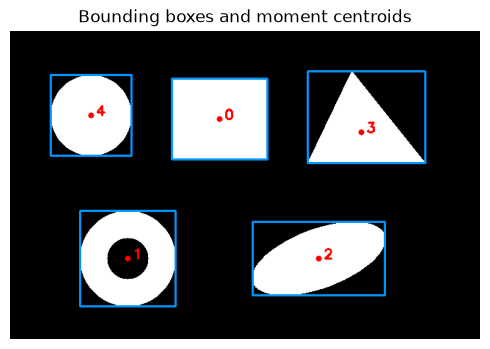

In [5]:
measure_view = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
for i, record in enumerate(records):
    x, y, w, h = record['box']
    cv2.rectangle(measure_view, (x, y), (x + w - 1, y + h - 1), (255, 150, 0), 2)
    if record['center'] is not None:
        cx, cy = map(round, record['center'])
        cv2.circle(measure_view, (cx, cy), 4, (0, 0, 255), -1)
        cv2.putText(measure_view, str(i), (cx + 7, cy), cv2.FONT_HERSHEY_SIMPLEX, .6, (0, 0, 255), 2)
show_images([measure_view], ['Bounding boxes and moment centroids'])


In [6]:
circle_mask = np.zeros((130, 130), np.uint8)
cv2.circle(circle_mask, (65, 65), 45, 255, -1)
circle_contours, _ = cv2.findContours(circle_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print('Nonzero pixel count:', cv2.countNonZero(circle_mask))
print('Polygon area:', cv2.contourArea(circle_contours[0]))
print('Ideal continuous circle area:', round(np.pi * 45**2, 2))
degenerate = np.array([[[0, 0]], [[10, 0]]], dtype=np.int32)
assert shape_record(degenerate)['center'] is None


Nonzero pixel count: 6361
Polygon area: 6234.0
Ideal continuous circle area: 6361.73


## Step 3 — Understand holes with contour hierarchy
`RETR_EXTERNAL` ignores hole boundaries. `RETR_TREE` returns every level. Each hierarchy row contains `[next, previous, first_child, parent]`; `-1` means absent. To measure a ring, subtract the hole contour area from its outer contour area. For arbitrarily nested shapes, alternate signs by depth.


In [7]:
tree_contours, tree_hierarchy = cv2.findContours(mask.copy(), cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
tree_hierarchy = tree_hierarchy[0]
print('index: [next, previous, first_child, parent]')
for i, h in enumerate(tree_hierarchy):
    print(i, ':', h.tolist())
hole_ids = [i for i, h in enumerate(tree_hierarchy) if h[3] >= 0]
print('Hole contour IDs for this simple scene:', hole_ids)
assert len(hole_ids) == 1


index: [next, previous, first_child, parent]
0 : [1, -1, -1, -1]
1 : [3, 0, 2, -1]
2 : [-1, -1, -1, 1]
3 : [4, 1, -1, -1]
4 : [5, 3, -1, -1]
5 : [-1, 4, -1, -1]
Hole contour IDs for this simple scene: [2]


Ring area estimated from boundary polygons: 10558.0


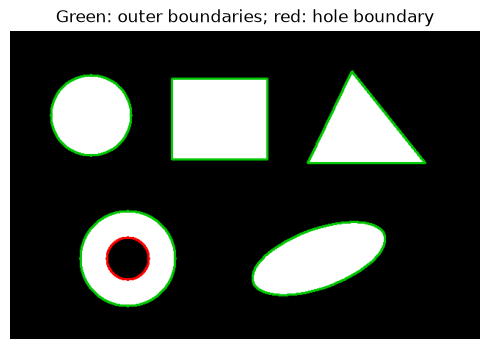

In [8]:
tree_view = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
for i, contour in enumerate(tree_contours):
    color = (0, 0, 255) if tree_hierarchy[i, 3] >= 0 else (0, 200, 0)
    cv2.drawContours(tree_view, [contour], -1, color, 2)
hole_id = hole_ids[0]
parent_id = int(tree_hierarchy[hole_id, 3])
ring_area = cv2.contourArea(tree_contours[parent_id]) - cv2.contourArea(tree_contours[hole_id])
print('Ring area estimated from boundary polygons:', ring_area)
show_images([tree_view], ['Green: outer boundaries; red: hole boundary'])


## Step 4 — Approximate geometry and inspect tolerance
`approxPolyDP` simplifies a contour. Set epsilon as a fraction of perimeter so it scales with object size. A small epsilon preserves detail; a large one can turn a circle into a few-sided polygon. Vertex count is therefore a feature with a tolerance, not an infallible class label.


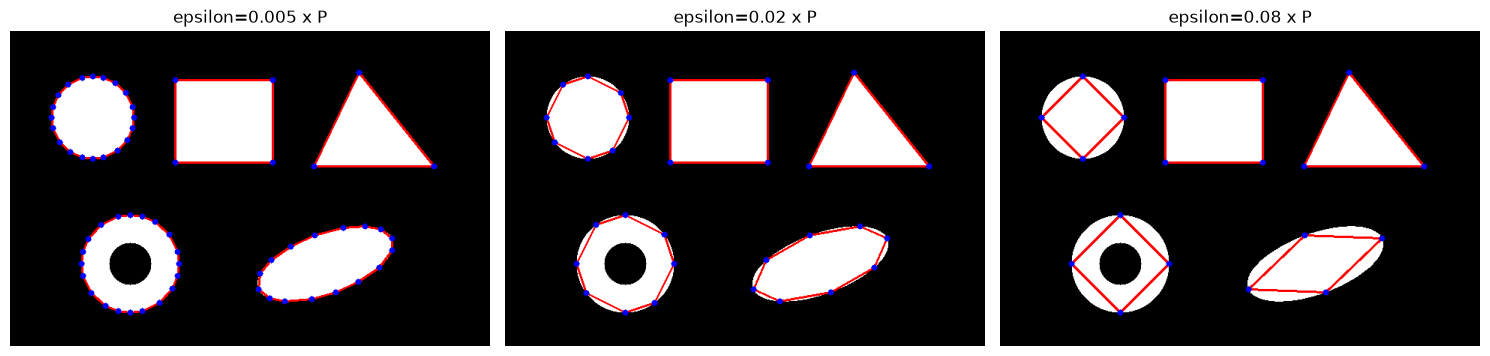

In [9]:
approx_views = []
for fraction in [.005, .02, .08]:
    view = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
    for contour in contours:
        approx = cv2.approxPolyDP(contour, fraction * cv2.arcLength(contour, True), True)
        cv2.polylines(view, [approx], True, (0, 0, 255), 2)
        for point in approx[:, 0]:
            cv2.circle(view, tuple(point), 4, (255, 0, 0), -1)
    approx_views.append(view)
show_images(approx_views, ['epsilon=0.005 x P', 'epsilon=0.02 x P', 'epsilon=0.08 x P'])


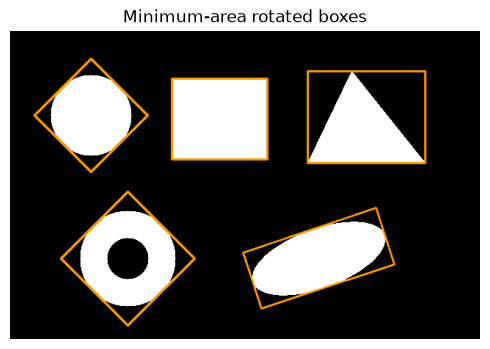

In [10]:
rotated_view = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
for contour in contours:
    rotated_rect = cv2.minAreaRect(contour)
    corners = np.rint(cv2.boxPoints(rotated_rect)).astype(np.int32)
    cv2.polylines(rotated_view, [corners], True, (0, 150, 255), 2)
show_images([rotated_view], ['Minimum-area rotated boxes'])


## Step 5 — Mini-project: inspect synthetic parts
Use several interpretable features: vertex count for triangles/quadrilaterals, circularity for round shapes, and contour hierarchy for holes. Circularity of a raster circle is usually below 1. The following thresholds are tuned to our generated scene; real parts need representative validation data.


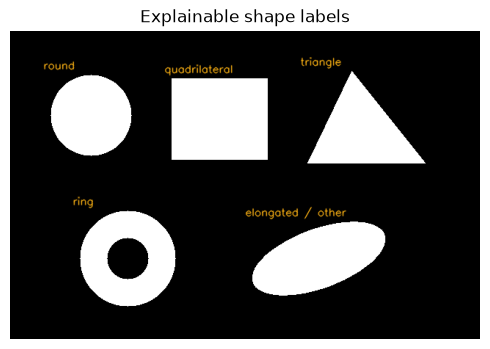

In [11]:
def classify_outer(contour, has_hole=False):
    record = shape_record(contour)
    approximation = cv2.approxPolyDP(contour, .02 * record['perimeter'], True)
    if has_hole:
        return 'ring'
    if len(approximation) == 3:
        return 'triangle'
    if len(approximation) == 4:
        return 'quadrilateral'
    if record['circularity'] > .82:
        return 'round'
    return 'elongated / other'

inspection = cv2.cvtColor(mask, cv2.COLOR_GRAY2BGR)
labels = []
for i, contour in enumerate(tree_contours):
    if tree_hierarchy[i, 3] != -1:
        continue
    label = classify_outer(contour, has_hole=tree_hierarchy[i, 2] != -1)
    labels.append(label)
    x, y, w, h = cv2.boundingRect(contour)
    cv2.putText(inspection, label, (max(0, x - 10), max(20, y - 8)),
                cv2.FONT_HERSHEY_SIMPLEX, .48, (20, 180, 255), 1, cv2.LINE_AA)
show_images([inspection], ['Explainable shape labels'])
assert 'ring' in labels and 'triangle' in labels


In [12]:
out_dir = ROOT / 'outputs' / '08_contours'
out_dir.mkdir(parents=True, exist_ok=True)
save_image(out_dir / 'part_inspection.png', inspection)
print('Saved inspection to', out_dir)


Saved inspection to C:\Users\Hareram ray\AI\OpencvPractical\outputs\08_contours


### Stress test: add small specks
Noise can create many valid but irrelevant contours. A minimum area removes tiny components. This filter is stated in pixel²; it must change if image scale changes.


All contours: 71 | area > 500: 5


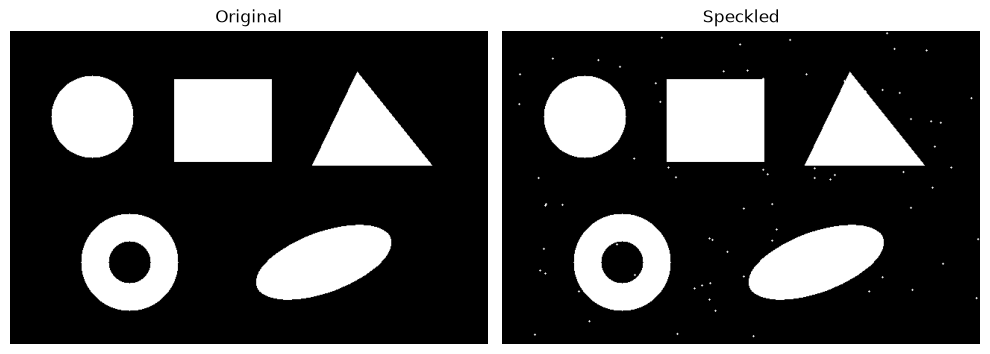

In [13]:
speckled = mask.copy()
for x, y in rng.integers([0, 0], [640, 420], size=(90, 2)):
    cv2.circle(speckled, (int(x), int(y)), 1, 255, -1)
noisy_contours, _ = cv2.findContours(speckled, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
large_contours = [c for c in noisy_contours if cv2.contourArea(c) > 500]
print('All contours:', len(noisy_contours), '| area > 500:', len(large_contours))
show_images([mask, speckled], ['Original', 'Speckled'], cols=2)


### Pitfalls and practice
- Contour ordering is not a stable identity. Sort or match by geometry when needed.
- Centroids can fall outside a concave shape or inside its hole.
- An external contour's area includes its enclosed holes unless you account for hierarchy.

1. Return all parts whose axis-aligned aspect ratio exceeds 1.5.
2. Compute net polygon area across the entire hierarchy using depth parity.
3. Double the scene size with nearest-neighbor interpolation. Compare contour area scaling to perimeter scaling.


## Worked solutions
Use depth parity for nested contours: outer boundary (+), hole (−), island inside a hole (+).


In [14]:
wide_ids = [i for i, r in enumerate(records) if r['aspect'] > 1.5]
print('Wide external contour IDs:', wide_ids)

net_area = 0.0
for i, contour in enumerate(tree_contours):
    depth, parent = 0, int(tree_hierarchy[i, 3])
    while parent != -1:
        depth += 1
        parent = int(tree_hierarchy[parent, 3])
    net_area += (-1)**depth * cv2.contourArea(contour)
print('Net polygon area:', net_area)
print('Foreground pixel area:', cv2.countNonZero(mask))


Wide external contour IDs: [2]
Net polygon area: 56095.0
Foreground pixel area: 57162


In [15]:
large_mask = cv2.resize(mask, None, fx=2, fy=2, interpolation=cv2.INTER_NEAREST)
large_cs, _ = cv2.findContours(large_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
large_cs = sorted(large_cs, key=cv2.contourArea, reverse=True)
print('Largest-part area ratio:', cv2.contourArea(large_cs[0]) / cv2.contourArea(contours[0]))
print('Largest-part perimeter ratio:', cv2.arcLength(large_cs[0], True) / cv2.arcLength(contours[0], True))
print('Expect approximately 4x area and 2x perimeter; raster boundaries cause small differences.')


Largest-part area ratio: 4.033636363636363
Largest-part perimeter ratio: 2.0083333333333333
Expect approximately 4x area and 2x perimeter; raster boundaries cause small differences.


### Reflection
Which feature changes if you rotate an elongated object: axis-aligned aspect ratio, circularity, or both? What evidence would you collect before trusting these rules on photographed parts?

Official references: [Contour features](https://docs.opencv.org/4.x/dd/d49/tutorial_py_contour_features.html), [Contour properties](https://docs.opencv.org/4.x/d1/d32/tutorial_py_contour_properties.html), [Hierarchy](https://docs.opencv.org/4.x/d9/d8b/tutorial_py_contours_hierarchy.html).
